# 20万元A股研究：证据审计

## tl;dr

本地保存的有效前瞻成熟日期为0；现有重排没有确立收益优势。优先验证新增盈利改善公告后的20日延续，但该假设尚无本系统实测结果。本笔记本复算既有证据，不运行新的策略回测。

## Context & Methods

决策是下一阶段研究资源投向哪里。资金为用户提供的20万元人民币。

### Key Assumptions

最近价格对照是迟发回顾，股票×预测日不是独立交易。上涨初期CSV的execution_return_pct含预测选定日最高价，其名字不能作为可执行收益证明。全股票池结论仅审阅原报告及审计回执。新协议的10%回撤和20日窗口为提案，未获用户风险偏好确认。

### 1. 读取有哈希的本地证据

从quant-research目录运行。

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
assert (root / 'src/quant_research').is_dir()
sys.path.insert(0, str(root / 'scripts'))
from audit_edge_opportunity import audit
evidence = audit(root)
output_dir = root / 'artifacts/edge-opportunity-20261012-v2'
print('行情截止:', evidence['price_observed_through'])
print('保存的前瞻成熟日期:', evidence['saved_prospective_mature_dates'])
print('复核通过项:', len(evidence['checks_passed']))

行情截止: 2026-09-28
保存的前瞻成熟日期: 0
复核通过项: 4


## Data

数据仅来自本地既有日报、逐日重排结果、全股票池审计及源代码。没有刷新市场数据，也没有读取封存测试标签。

In [2]:
from IPython.display import display, HTML, Image
from html import escape
def show_table(rows, columns):
    head = ''.join('<th>' + escape(label) + '</th>' for _, label in columns)
    body = ''
    for row in rows:
        values = []
        for key, _ in columns:
            value = row.get(key)
            text = format(value, '.4f') if isinstance(value, float) else str(value)
            values.append('<td>' + escape(text) + '</td>')
        body += '<tr>' + ''.join(values) + '</tr>'
    display(HTML('<table><thead><tr>' + head + '</tr></thead><tbody>' + body + '</tbody></table>'))
print('逐日重排窗口:', evidence['early_stage_results_recomputed'][0]['start'], evidence['early_stage_results_recomputed'][0]['end'])
print('证据文件数:', len(evidence['sources']))

逐日重排窗口: 2024-07-01 2025-07-22
证据文件数: 15


## Results

### 2. 最近收盘预测对照

In [3]:
price_rows = evidence['price_results_recomputed']
show_table(price_rows, [('arm', '榜单'), ('known_stock_forecast_day_rows', '可对照记录'), ('model_mape_pct', '模型MAPE %'), ('baseline_mape_pct', '原收盘基线MAPE %')])

榜单,可对照记录,模型MAPE %,原收盘基线MAPE %
control,180,10.2458,7.9172
start_stage,100,5.2809,5.2802


主榜误差较原收盘基线更高；上涨初期基本持平。两个榜单的股票、日期群体不同，表间差值不能证明筛选的增量收益。

### 3. 同日期重排的情景差值

重排,历史日期,相对对照变化 pp,改善日期比例
combined,196,-1.0884,0.3571
early_stage,196,-0.0149,0.2908
overheat_penalty,196,-0.0962,0.3469


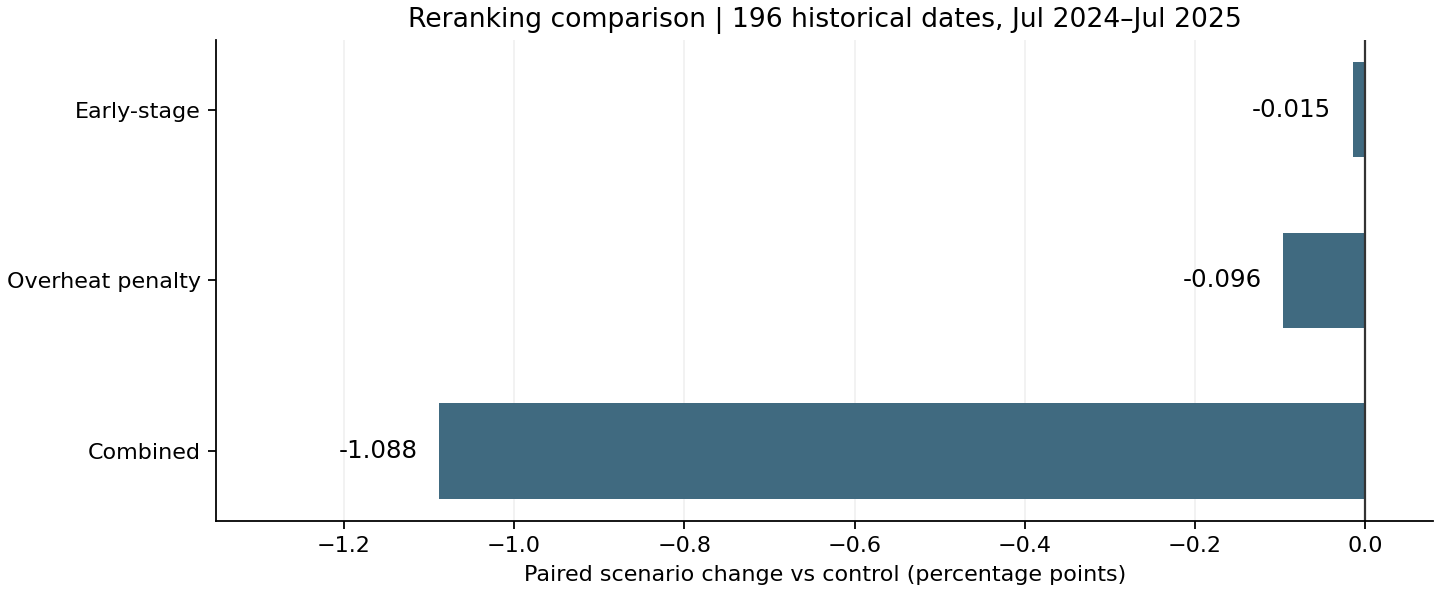

In [4]:
scenario_rows = [r for r in evidence['early_stage_results_recomputed'] if r['arm'] != 'control']
show_table(scenario_rows, [('arm', '重排'), ('date_count', '历史日期'), ('paired_mean_change_pp', '相对对照变化 pp'), ('improved_date_fraction', '改善日期比例')])
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
labels = {'early_stage':'Early-stage', 'overheat_penalty':'Overheat penalty', 'combined':'Combined'}
ordered = sorted(scenario_rows, key=lambda row: row['paired_mean_change_pp'])
fig, ax = plt.subplots(figsize=(9, 3.7), layout='constrained')
values = [r['paired_mean_change_pp'] for r in ordered]
bars = ax.barh([labels[r['arm']] for r in ordered], values, color='#406a80', height=0.56)
ax.axvline(0, color='#333333', linewidth=1)
ax.set_xlim(-1.35, 0.08)
ax.set_xlabel('Paired scenario change vs control (percentage points)')
ax.set_title('Reranking comparison | 196 historical dates, Jul 2024–Jul 2025')
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='x', alpha=0.18)
ax.set_axisbelow(True)
for bar, value in zip(bars, values):
    ax.text(value - 0.025, bar.get_y() + bar.get_height()/2, format(value, '+.3f'), ha='right', va='center', fontsize=11)
fig.savefig(output_dir / 'reranking-scenario-deltas.png', dpi=160)
display(Image(filename=str(output_dir / 'reranking-scenario-deltas.png')))
plt.close(fig)

这些是下一日开盘到模型选定日最高价的情景差异，不是账户净收益。原比较的1e-10个百分点平局容差已保持一致。三种重排的平均情景差均为负。

### 4. 正式收益验证的数据资格

In [5]:
show_table([{'field': k, 'value': v} for k, v in evidence['input_status']['declaration'].items()], [('field', '声明项'), ('value', '当前保存值')])
print('formal_ready:', evidence['input_status']['formal_ready'])
print('纳入的及时发布记录:', sum(r['prospective'] for r in evidence['publications']))

声明项,当前保存值
purpose,training
vintage,reconstructed
synthetic,False
st_history_verified,False
actions_verified,False
rules_verified,False
historical_universe_verified,False
industry_history_verified,False


formal_ready: False
纳入的及时发布记录: 0


声明字段不能代替源证据。当前保存输入为训练用途，不能据此通过真实成本后收益验收。

## Takeaways

1. 保留模型预测误差改善的证据，停止把高低价情景解释为盈利。
2. 优先补新增业绩预告数值与真实可见时间，验证事件本身的增量。
3. 新实验先四组固定对照，20万元完整账户，20日为主要持有期。
4. 120交易日只审查运营，252交易日做唯一正式统计判定。

完整方案见docs/edge-opportunity-and-validation-20261012.md；结构化协议仍为设计规范，尚未接入现有runner。

### 来源与复算轨迹

In [6]:
show_table(evidence['sources'], [('file', '证据文件'), ('sha256', 'SHA-256')])

证据文件,SHA-256
artifacts/daily-token-live-v2/research-latest.json,56da82fa8a66990e71debe8c637065d19621abd6c95eb6b3ae3bd51a5cd04257
artifacts/daily-token-live-v2/current.json,6822fca1212adbb4039ade03dec66689734f41491002b4415c74d3fbb884aa21
artifacts/daily-token-live-v2/data/2026-09-28/input/snapshot/manifest.json,cea12f399a34b3f8423ac4d84d729ef172ddeefa4acca669ec731e472e10e537
artifacts/daily-token-live-v2/data/2026-09-28/input/refresh-summary.json,a767ceb67b9fce3d889fc571eec590195d5c09f37102c723a9d48f9fc76906c6
artifacts/retrained-early-stage-20260922-v1/daily.csv,c89f868d319d652afb481fbeb86301dee07837fb2f6e8b3a9b5518c2dc5aeb1d
artifacts/retrained-early-stage-20260922-v1/summary.csv,83f95c1883731108c470a484069f4add5e4948edb7ad9d7e47b99d8faff4f71a
artifacts/retrained-early-stage-20260922-v1/decision.json,607fa7506fb22adc00a421046a2c9b6e6966b699e26a2ad41fb8d90e27fdbc0e
artifacts/token-three-ideas-20260917-v1/completion-audit/conclusions.md,8f08f1409f1480f259ba4ec773d1a5652b34d8f43c0547ce25500f4b1fe1980b
artifacts/token-three-ideas-20260917-v1/completion-audit/verification.json,9e9c1aaa7c57a78b7da5397e8f8436cb41ae200dbe8797692bf5cab2d5f0aaee
docs/plan-risk-decision-20260914.md,7512b771192398e9940033a66a199ddf8dad407c76c720ae42b92d12ddec04e8
